## **Data Loading and Overview**

In [ ]:
# Import necessary libraries
import kagglehub
import os
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Set the style of matplotlib
%matplotlib inline
plt.style.use('fivethirtyeight')

In [ ]:
# Download dataset
path = kagglehub.dataset_download("mexwell/heart-disease-dataset")

print("Dataset downloaded to:", path)

In [ ]:
# Load Dataset
csv_path = os.path.join(path, "heart_statlog_cleveland_hungary_final.csv")

df = pd.read_csv(csv_path)
df.head()

In [ ]:
# Check if there are any missing values
df.isna().sum()

In [ ]:
# Check if there are duplicate rows
df.duplicated().sum()

In [ ]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)
df.duplicated().sum()

In [ ]:
# View the overall information of the dataset
df.info()

In [ ]:
# View the statistical description of the dataset
df.describe()

## **Exploratory Data Analysis**

In [ ]:
# Print the number of unique values for each column
for col in df.columns:
    print(f'{col} has {df[col].nunique()} values')

In [ ]:
# Target distribution
# Set the figure size and create a count plot
plt.figure(figsize=(10, 8))
ax = sns.countplot(x=df['target'], palette='pastel')

# Add labels to each bar in the plot
for p in ax.patches:
    ax.text(p.get_x()+p.get_width()/2, p.get_height()+3, f'{p.get_height()}', ha="center")

plt.show()

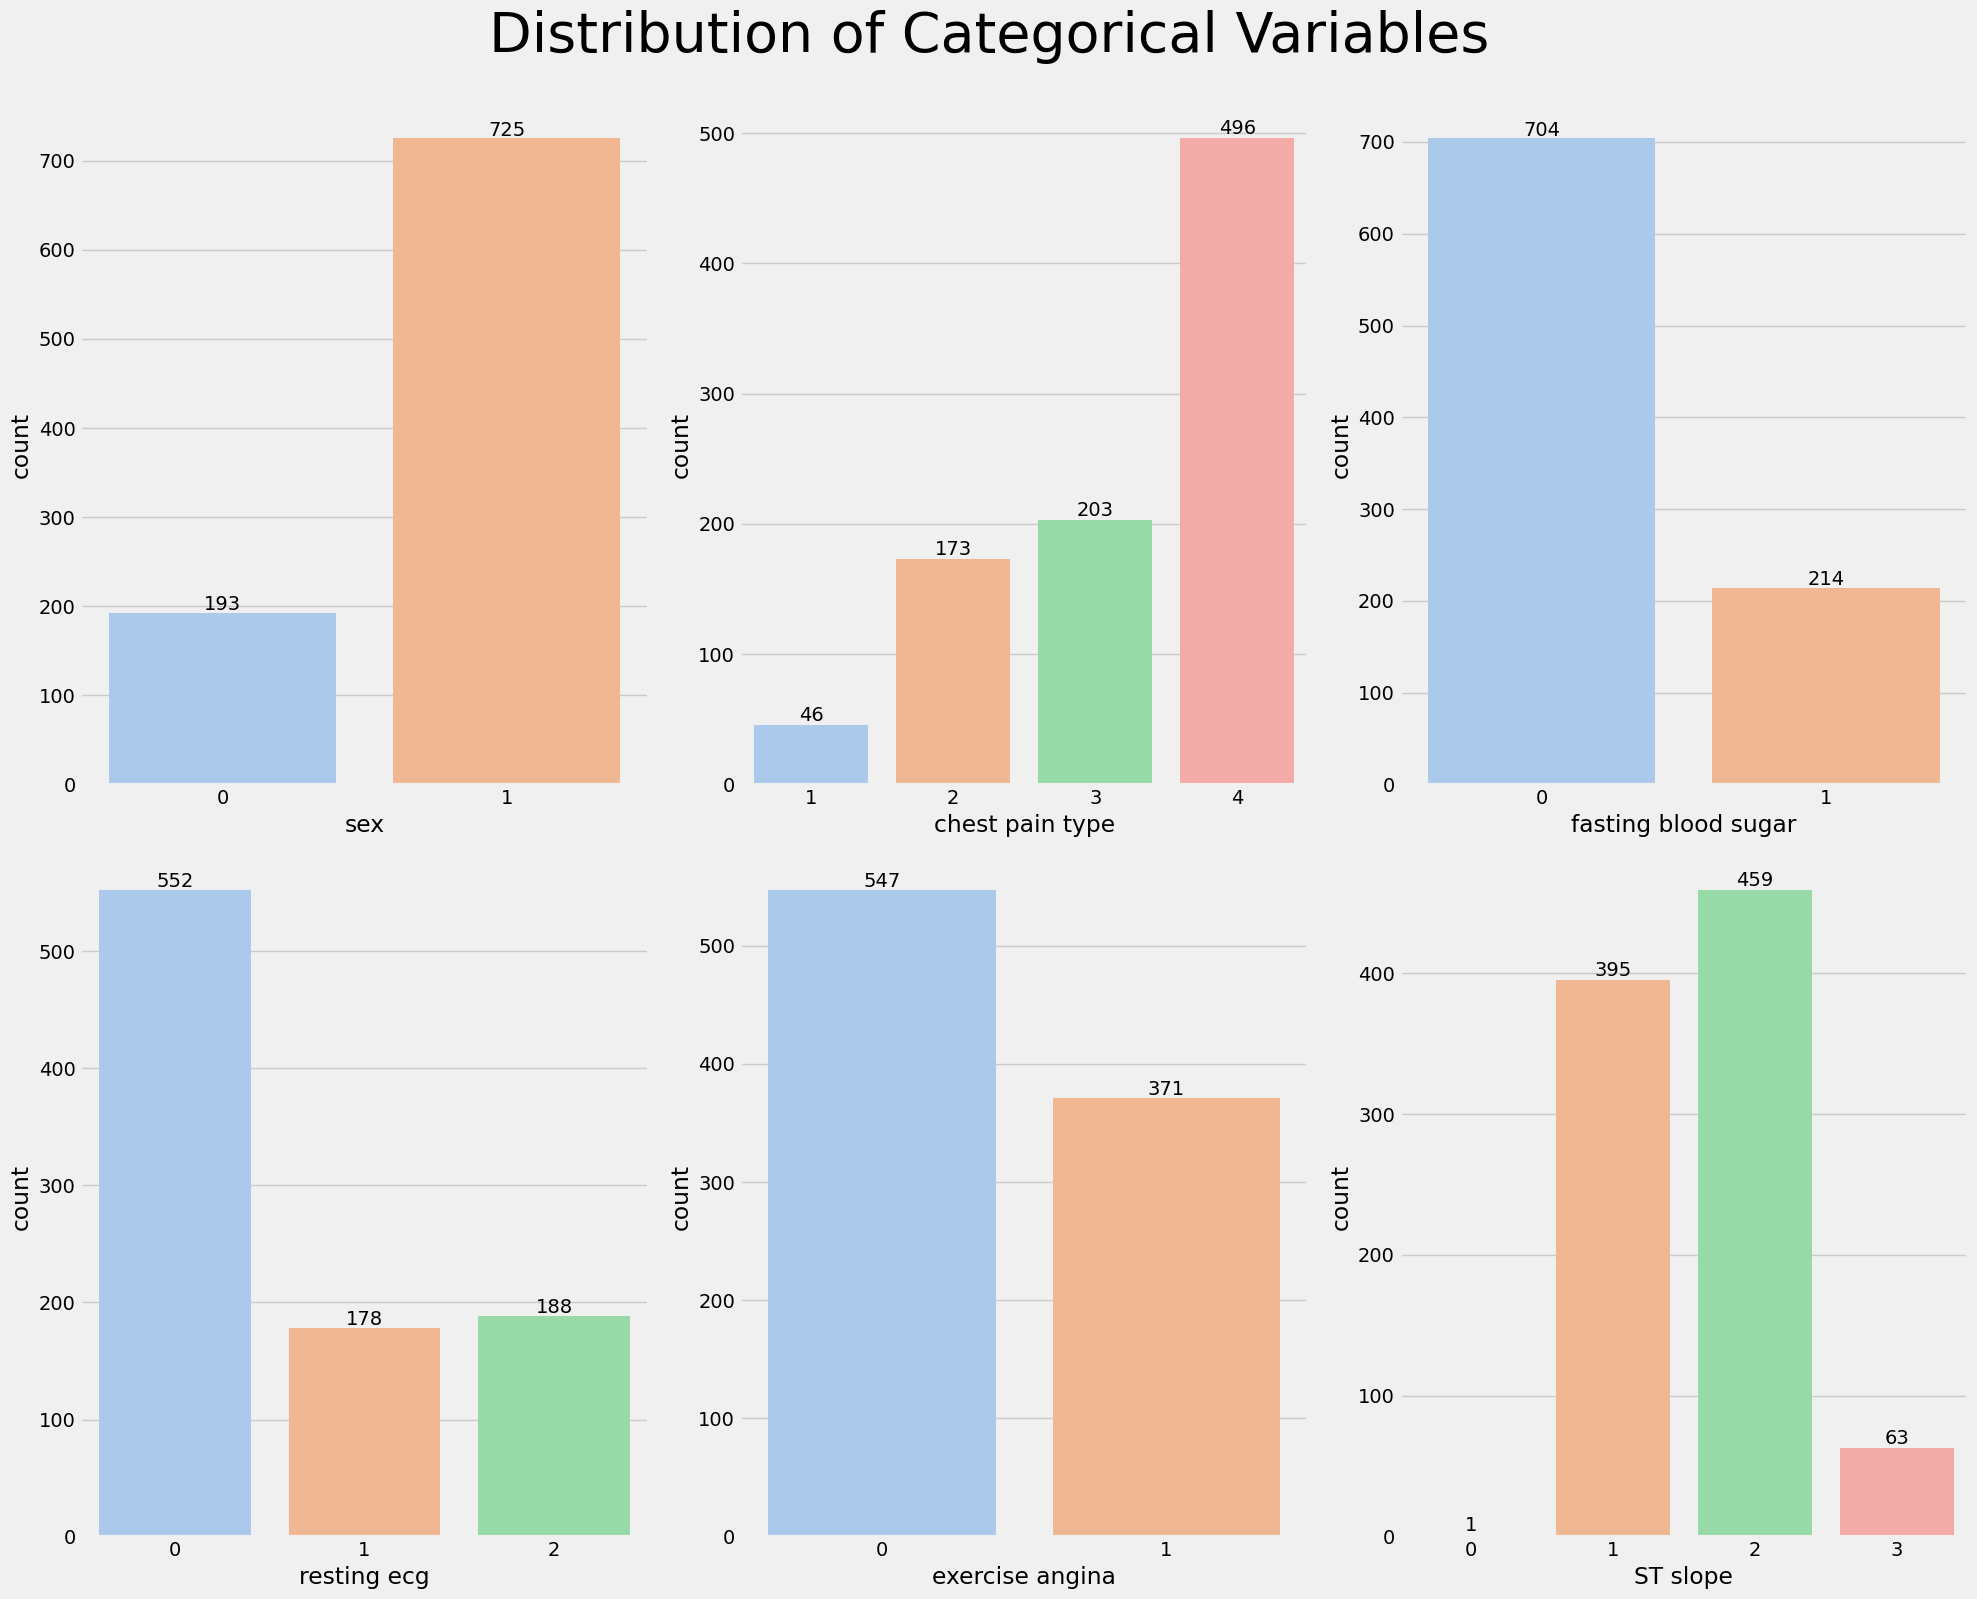

In [ ]:
# Distribution of categorical columns
plt.figure(figsize=(20, 16))
plotnumber = 1

for col in df.columns:
    # Check if the number of unique values is less than 5
    if df[col].nunique() < 5:
        if plotnumber <= 6:
            plt.subplot(2, 3, plotnumber)
            ax = sns.countplot(x=df[col], palette='pastel')

            # Add labels to each bar in the plot
            for p in ax.patches:
                ax.text(p.get_x()+p.get_width()/2, p.get_height()+3, f'{int(p.get_height())}', ha="center")

        plotnumber += 1

plt.suptitle('Distribution of Categorical Variables', fontsize=40, y=1)
plt.tight_layout()
plt.show()

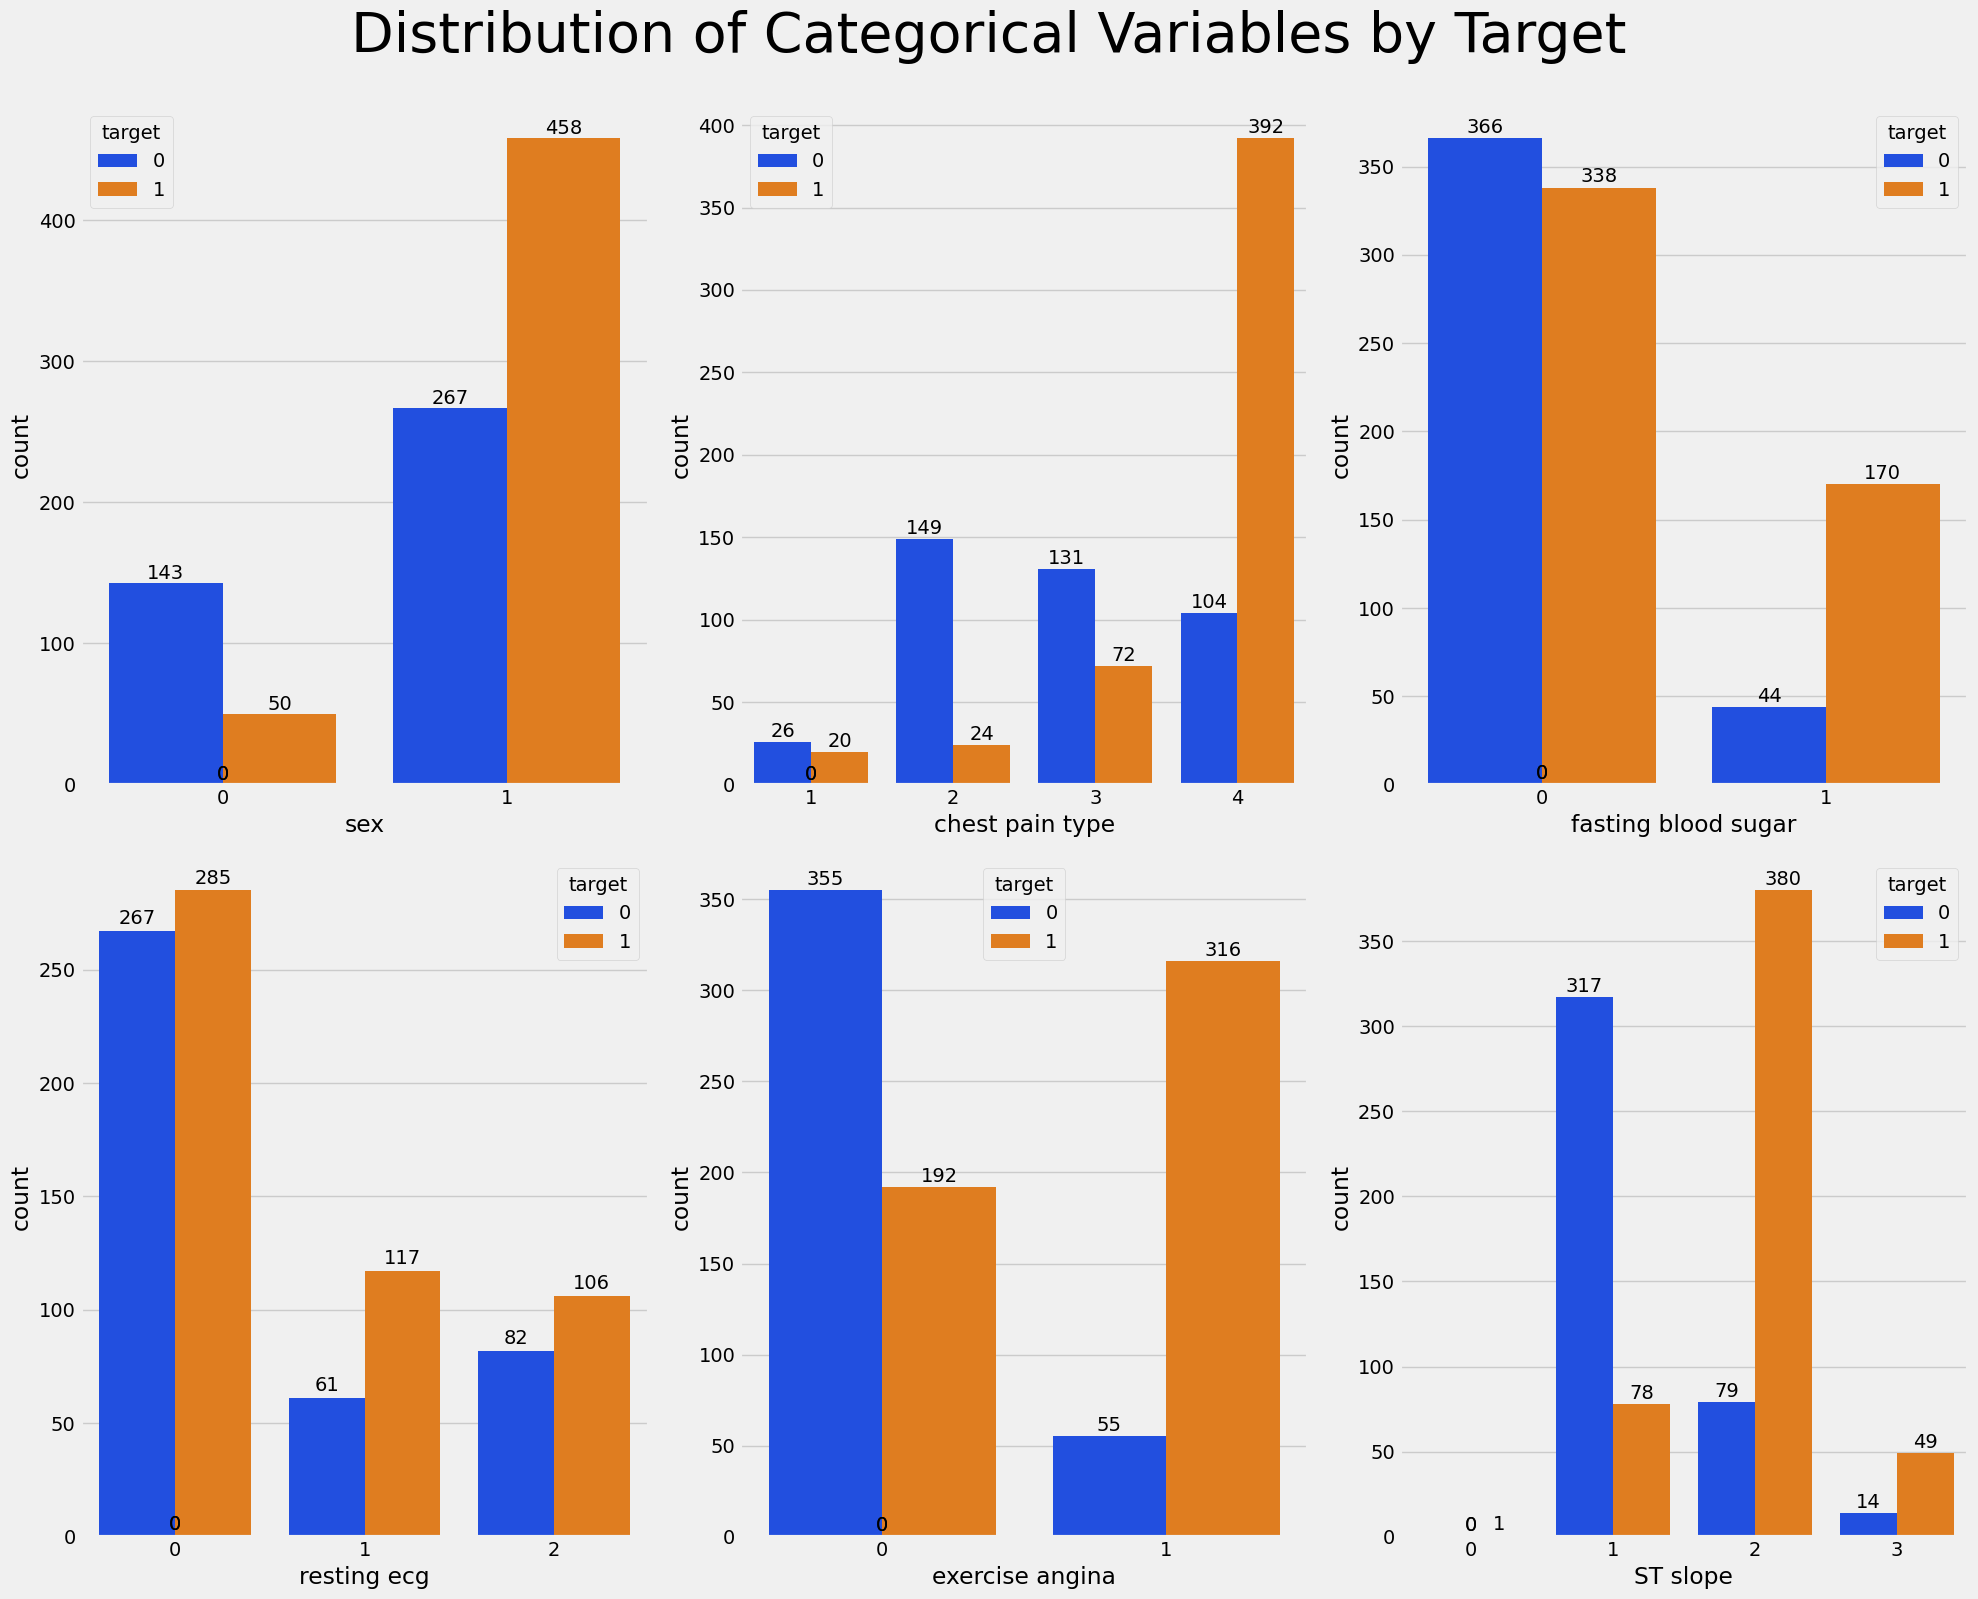

In [ ]:
plt.figure(figsize=(20, 16))
plotnumber = 1

# Loop through each column in the dataframe
for col in df.columns:
    # Check if the number of unique values is less than 5
    if df[col].nunique() < 5:
        if plotnumber <= 6:
            plt.subplot(2, 3, plotnumber)
            ax = sns.countplot(x=df[col], hue=df['target'], palette='bright')

            # Add labels to each bar in the plot
            for p in ax.patches:
                ax.text(p.get_x() + p.get_width() / 2.,
                        p.get_height() + 3,
                        f'{int(p.get_height())}',
                        ha="center")

        plotnumber += 1

plt.suptitle('Distribution of Categorical Variables by Target', fontsize=40, y=1)
plt.tight_layout()
plt.show()

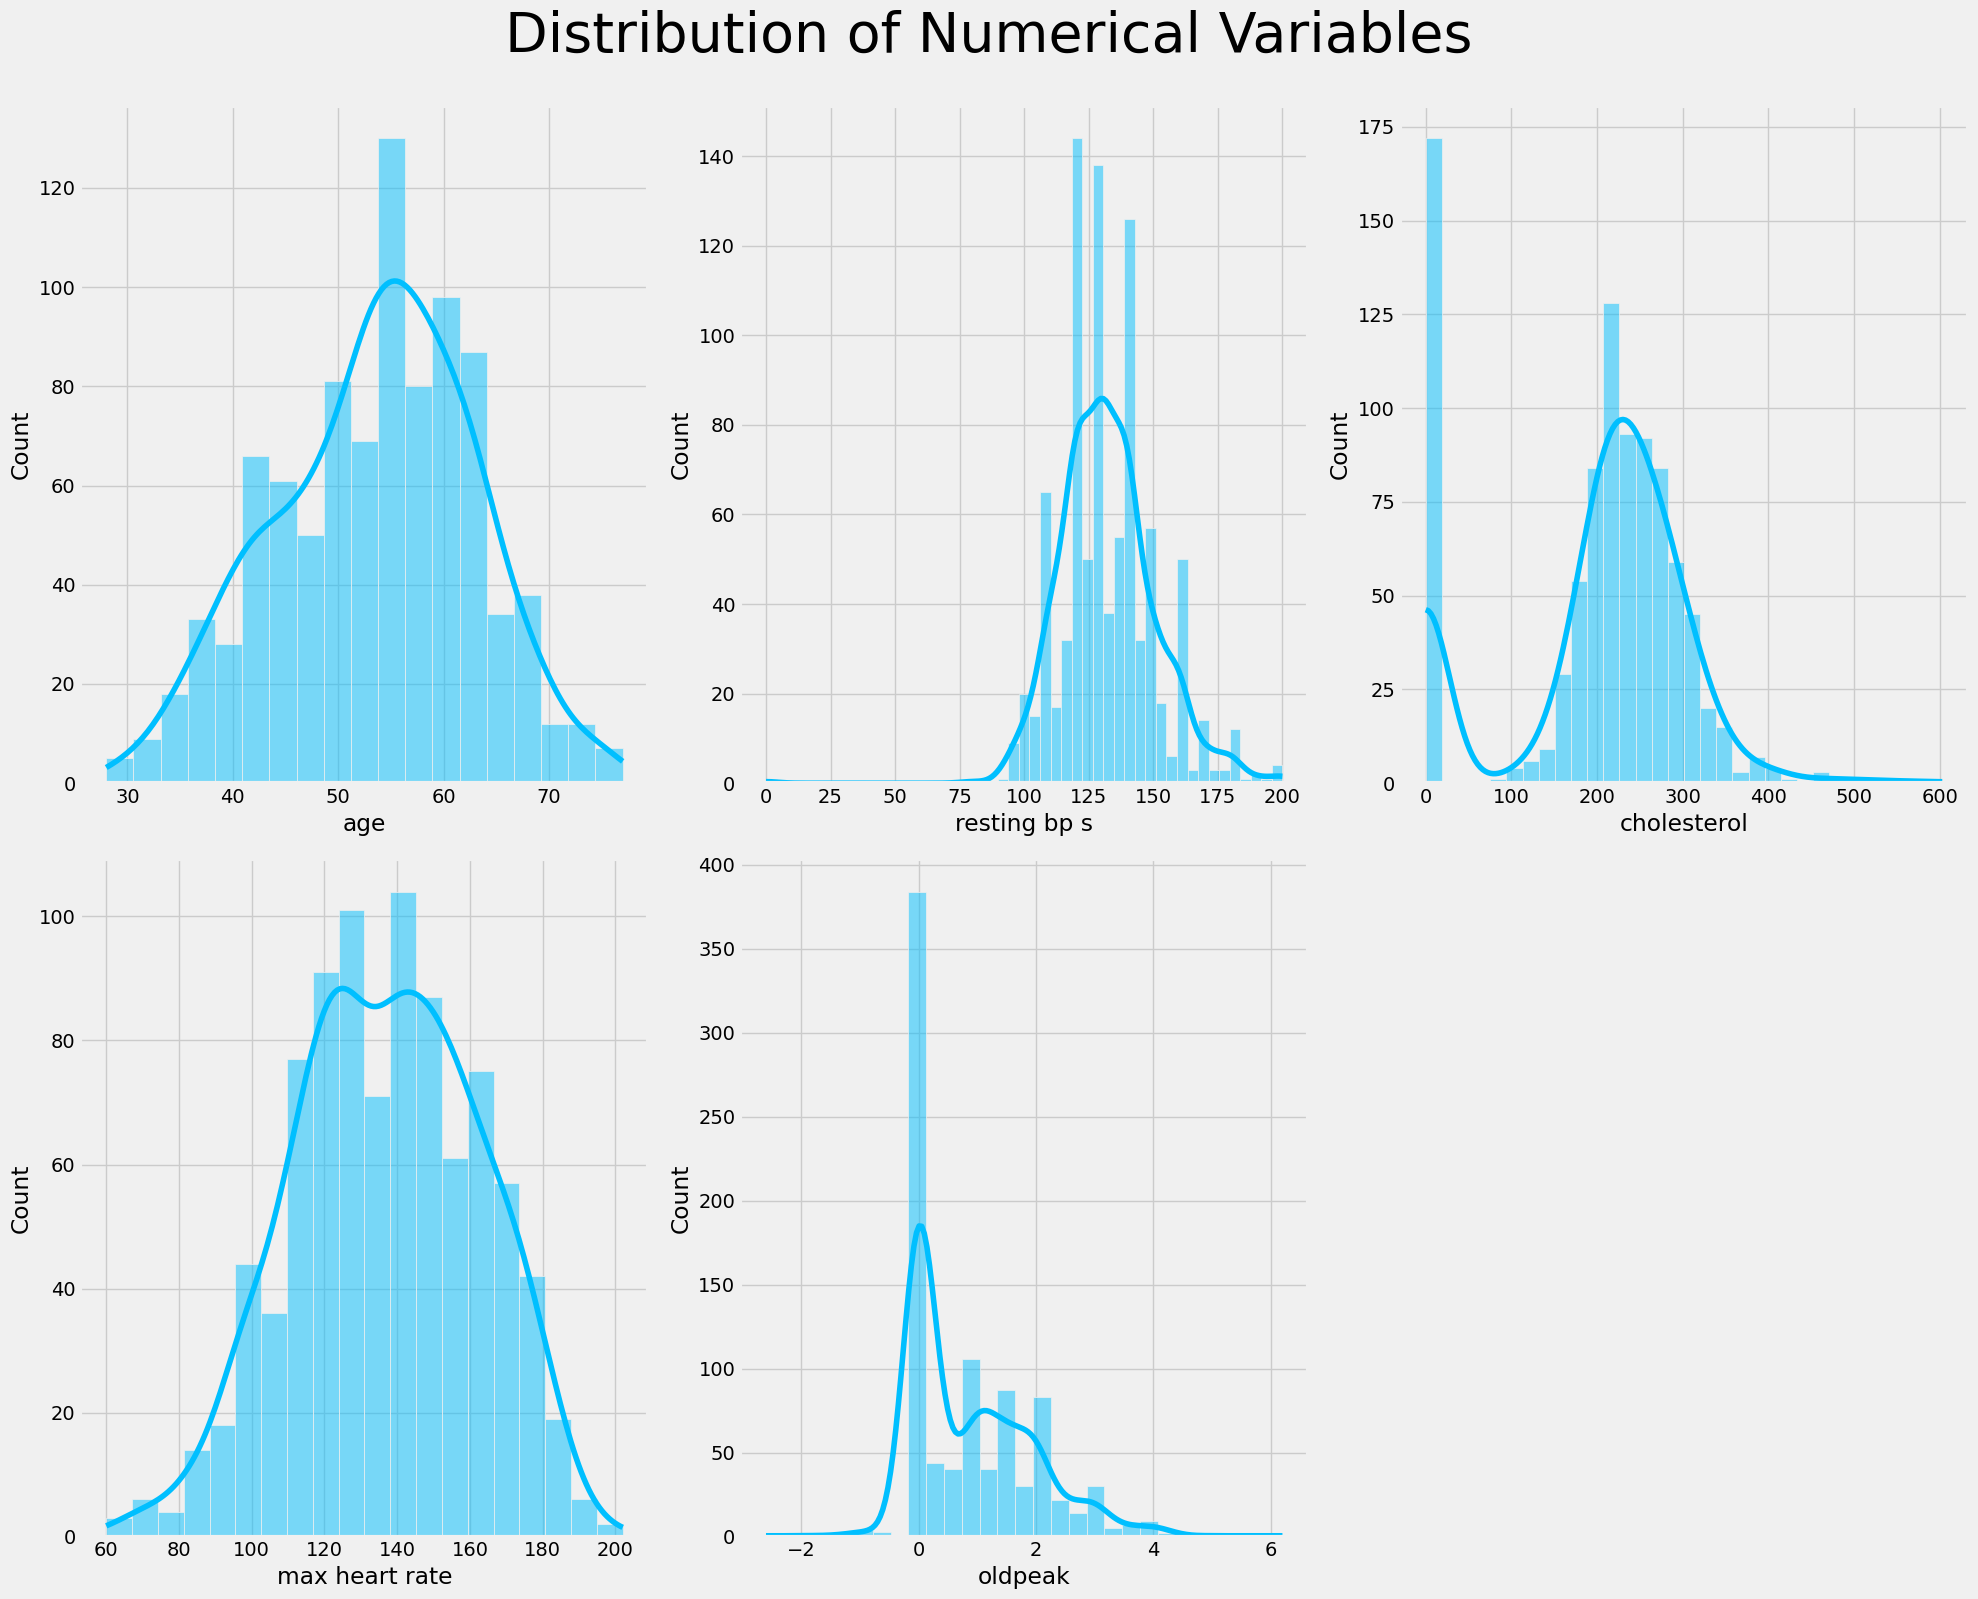

In [ ]:
# Distribution of numerical columns
plt.figure(figsize=(20, 16))
plotnumber = 1

for col in df.columns:
    # Check if the number of unique values is less than 5
    if df[col].nunique() > 5:
        plt.subplot(2, 3, plotnumber)
        sns.histplot(df[col], kde=True, color='deepskyblue')
        plt.xlabel(col)

        plotnumber += 1

plt.suptitle('Distribution of Numerical Variables', fontsize=40, y=1)
plt.tight_layout()
plt.show()

In [ ]:
# Replace zeros in the 'Serum Cholesterol' column with numpy.nan
# because zero is not a valid value for cholesterol levels
# and should be considered as missing data instead.
df['cholesterol'] = df['cholesterol'].replace(0, np.nan)
df['cholesterol'].isnull().sum()

np.int64(172)

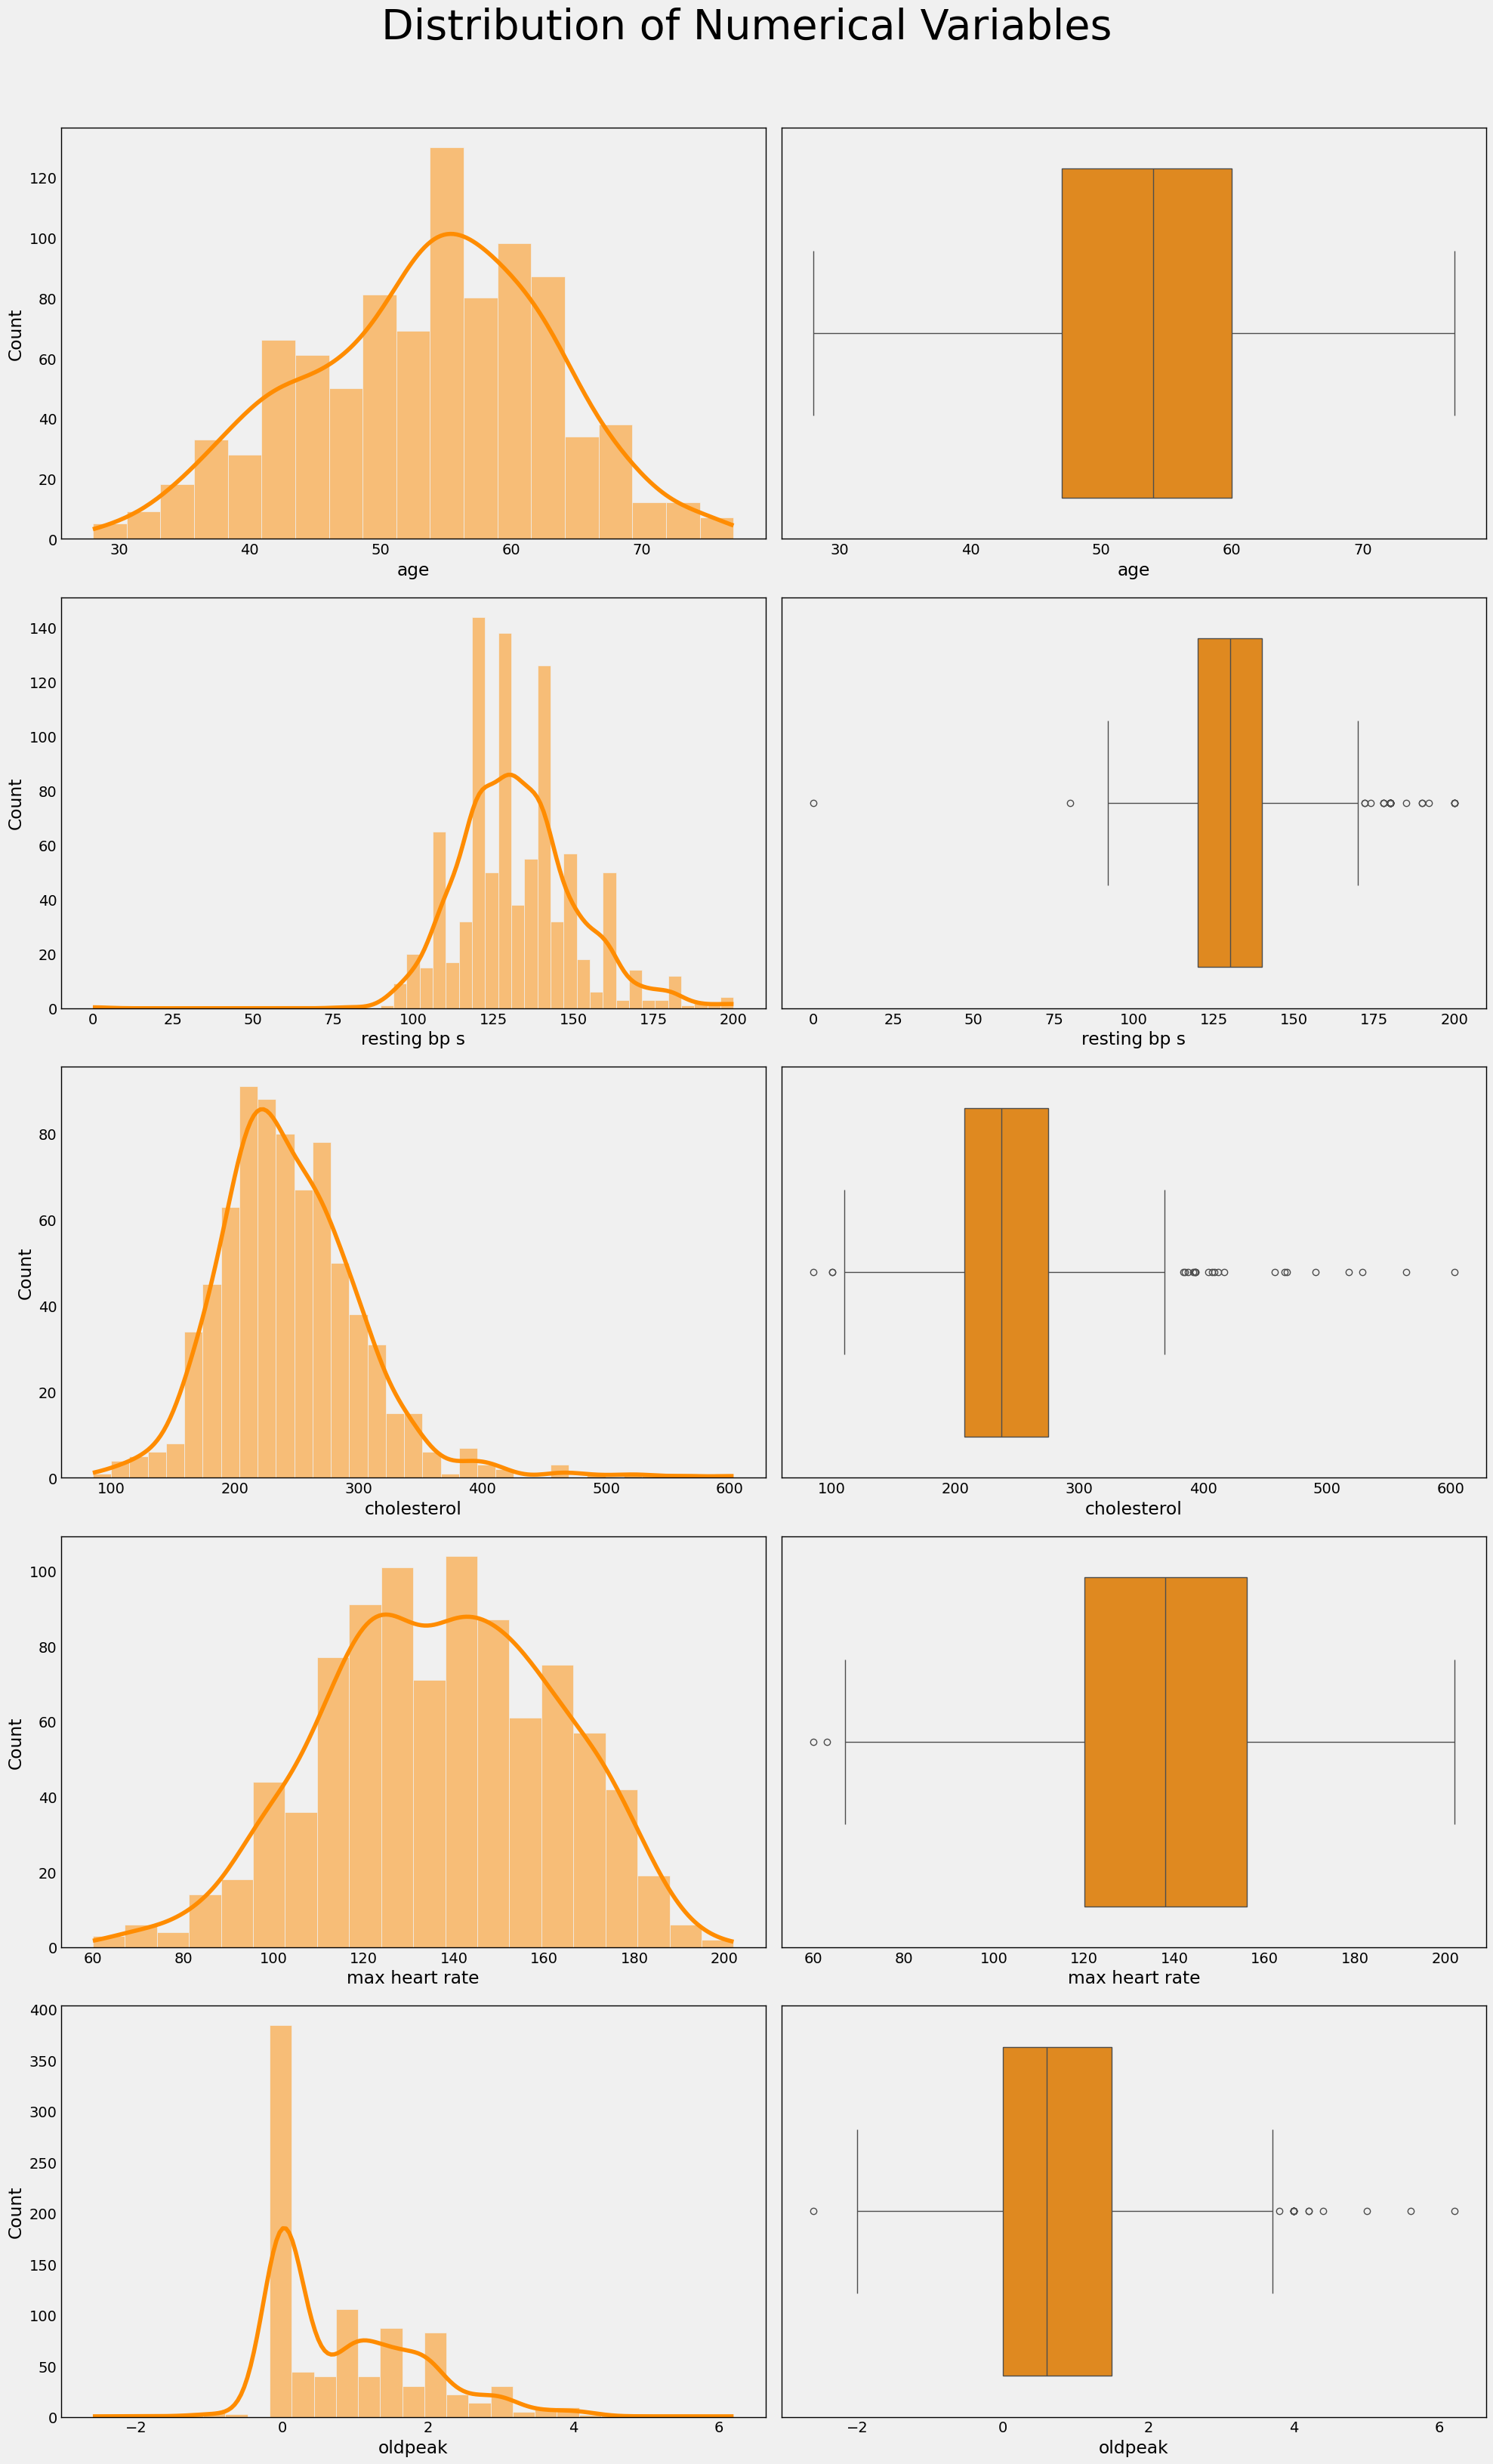

In [ ]:
plt.figure(figsize=(20, 32))
plotnumber = 1

# Select numerical columns with more than 5 unique values
num_columns = [col for col in df.columns if df[col].nunique() > 5]

# Create subplots for histograms and horizontal boxplots
for col in num_columns:
    # Histogram
    ax = plt.subplot(len(num_columns), 2, plotnumber)
    sns.histplot(df[col], kde=True, color='darkorange')
    plt.xlabel(col)
    plt.grid(False)

    # Add border to histogram using spines
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)

    plotnumber += 1

    # Boxplot
    ax = plt.subplot(len(num_columns), 2, plotnumber)
    sns.boxplot(x=df[col], color='darkorange', width=0.8, linewidth=1)
    plt.xlabel(col)
    plt.grid(False)

    # Add border to boxplot using spines
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)

    plotnumber += 1

# Set the main title and adjust layout
plt.suptitle('Distribution of Numerical Variables', fontsize=40, y=1.02)
plt.tight_layout()
plt.show()

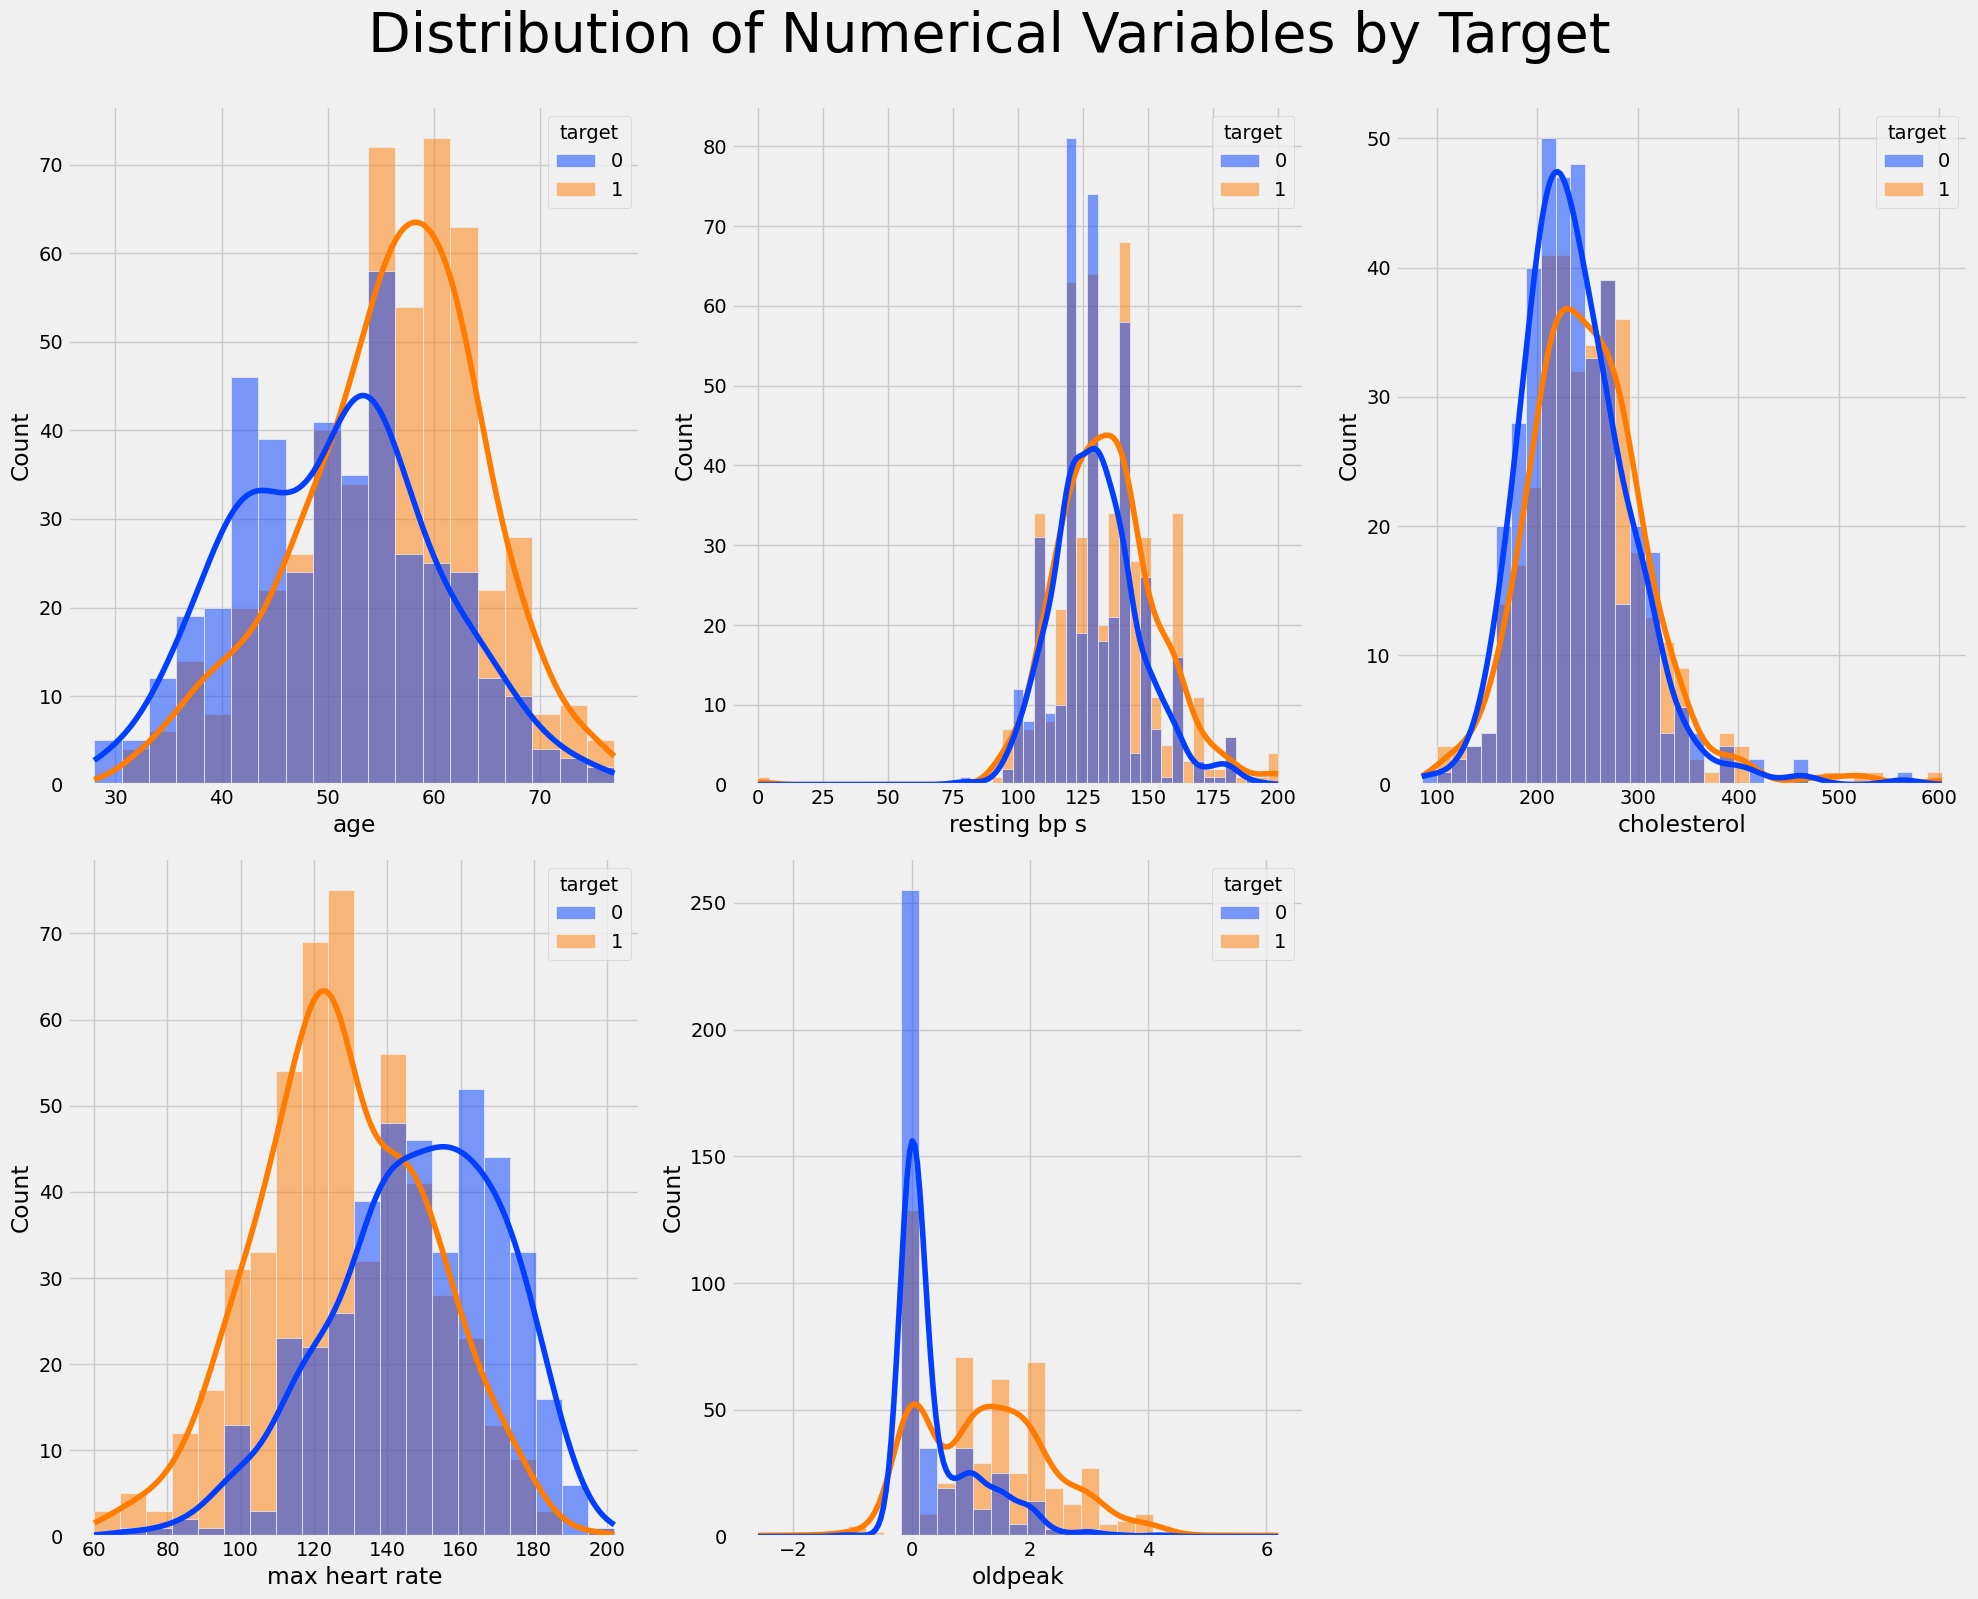

In [ ]:
plt.figure(figsize=(20, 16))
plotnumber = 1

# Loop through each column in the dataframe
for col in df.columns:
    # Check if the number of unique values is more than 5
    if df[col].nunique() > 5:
        plt.subplot(2, 3, plotnumber)
        sns.histplot(data=df, x=col, hue='target', kde=True, palette='bright')  # Use 'hue' to differentiate by target
        plt.xlabel(col)
        plotnumber += 1

# Set the main title and adjust layout
plt.suptitle('Distribution of Numerical Variables by Target', fontsize=40, y=1)
plt.tight_layout()
plt.show()

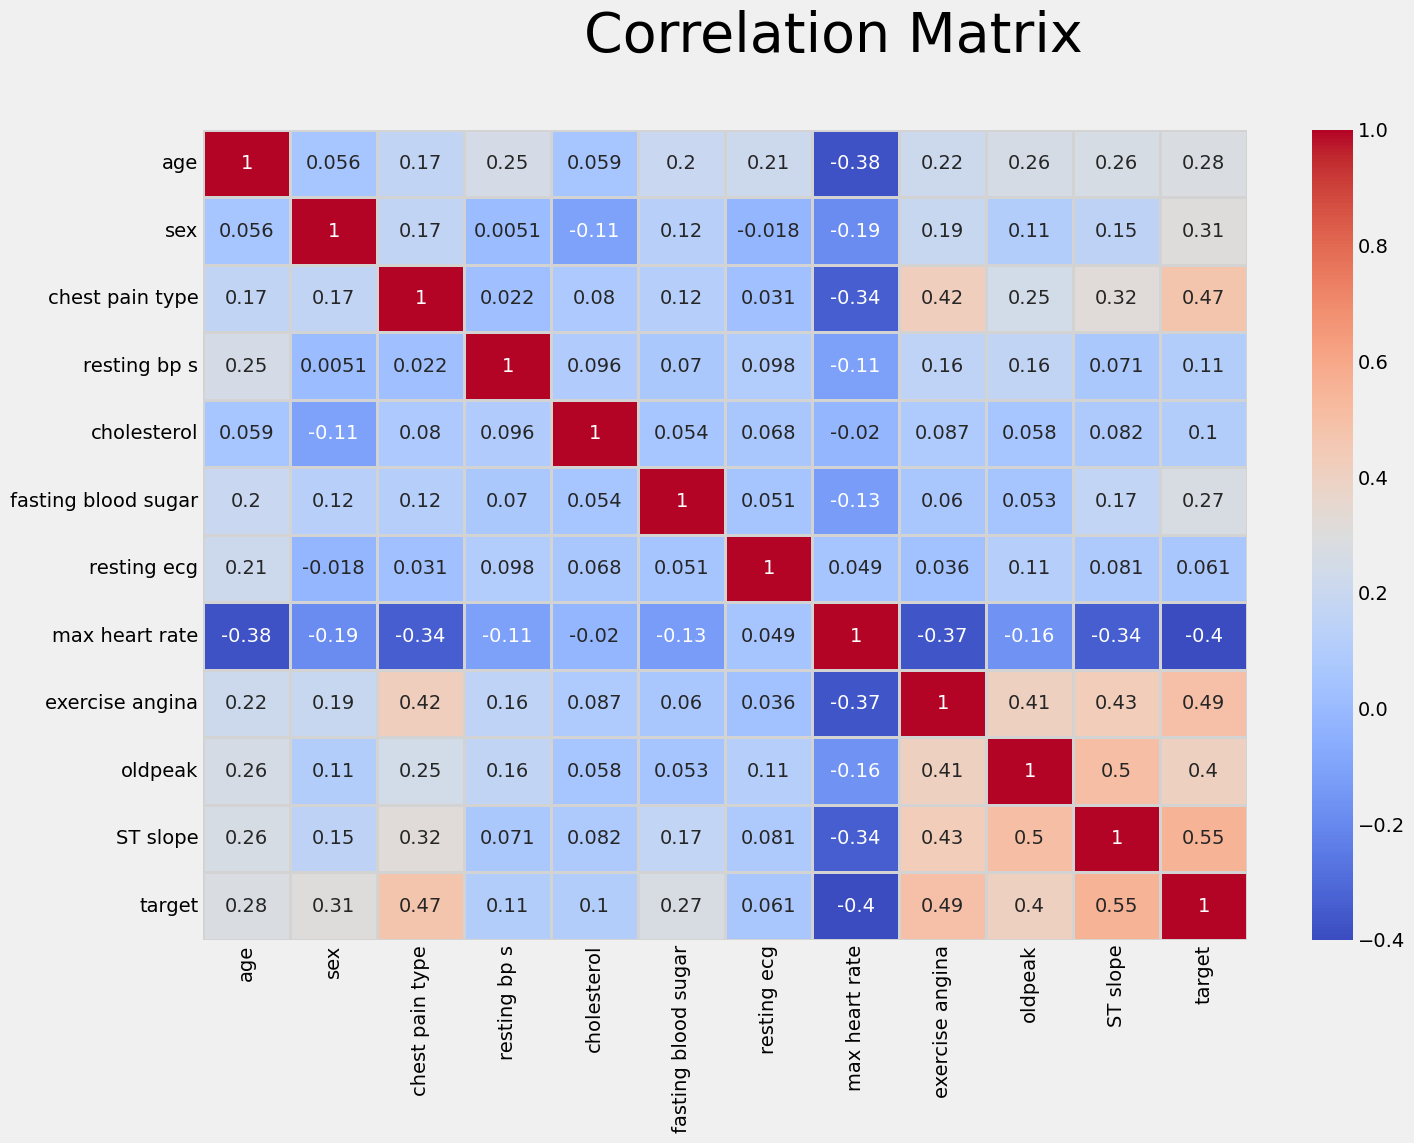

In [ ]:
# Correlation matrix
plt.figure(figsize=(15, 10))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', linewidths=2, linecolor='lightgrey')
plt.suptitle('Correlation Matrix', fontsize=40, y=1)
plt.show()

## **Feature Engineering**

In [ ]:
# Create descriptive statistical features
# Basic statistics: Providing the model with simple statistical descriptions of the raw data.
df['sum'] = df[df.columns].sum(axis=1)   # Sum of features
df['std'] = df[df.columns].std(axis=1)   # Standard deviation
df['mean'] = df[df.columns].mean(axis=1) # Mean
df['max'] = df[df.columns].max(axis=1)   # Maximum value
df['min'] = df[df.columns].min(axis=1)   # Minimum value
df['mode'] = df[df.columns].mode(axis=1)[0]  # Mode
df['median'] = df[df.columns].median(axis=1) # Median
df['q_25th'] = df[df.columns].quantile(0.25, axis=1) # 25th percentile
df['q_75th'] = df[df.columns].quantile(0.75, axis=1) # 75th percentile
df['skew'] = df[df.columns].skew(axis=1) # Skewness
df['kurt'] = df[df.columns].kurt(axis=1) # Kurtosis
df['range'] = df[df.columns].max(axis=1) - df[df.columns].min(axis=1)  # Range of feature values per row

In [ ]:
df

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,...,mean,max,min,mode,median,q_25th,q_75th,skew,kurt,range
0,40,1,2,140,289.0,0,0,172,0,0.0,...,105.542908,645.0,0.0,0.0,1.5,0.0,148.000000,2.135247,4.342134,645.0
1,49,0,3,160,180.0,0,0,156,0,1.0,...,90.069778,552.0,0.0,0.0,2.5,0.0,156.244222,2.152534,4.541174,552.0
2,37,1,2,130,283.0,0,1,98,0,0.0,...,90.658457,553.0,0.0,0.0,1.5,0.0,106.000000,2.137865,4.226918,553.0
3,48,0,4,138,214.0,0,0,108,1,1.5,...,84.527887,517.5,0.0,0.0,3.0,0.5,115.500000,2.185278,4.601234,517.5
4,54,1,3,150,195.0,0,0,122,0,0.0,...,85.854780,526.0,0.0,0.0,2.0,0.0,128.991730,2.178334,4.626720,526.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1185,45,1,1,110,264.0,0,0,132,0,1.2,...,91.194691,557.2,0.0,0.0,1.6,0.5,115.500000,2.157527,4.389003,557.2
1186,68,1,4,144,193.0,1,0,141,0,3.4,...,91.034996,558.4,0.0,0.0,3.7,1.0,141.750000,2.206148,4.772612,558.4
1187,57,1,4,130,131.0,0,0,115,1,1.2,...,72.220134,443.2,0.0,0.0,3.0,1.0,117.420469,2.208186,4.803548,443.2
1188,57,0,2,130,236.0,0,2,174,0,0.0,...,98.635129,604.0,0.0,0.0,2.0,0.0,140.722952,2.177251,4.594439,604.0


## **Modelling**

In [ ]:
# Prepare data
# Define independent variables
ind_col = [col for col in df.columns if col!='target']
# Define dependent variable
dep_col = 'target'

X = df[ind_col]
y = df[dep_col]

# For later use in feature importance plotting
dataframe = df[ind_col]

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Impute missing values BEFORE scaling
imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X)

# Then scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
from sklearn.model_selection import train_test_split

# Divide the data set into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(classifier, model_name, X_train, y_train, X_test, y_test):
    """
    Train, predict, and evaluate a classifier.

    Parameters:
        classifier: The machine learning classifier to train and evaluate.
        model_name: A string representing the name of the model for display.
        X_train, y_train: Training data and labels.
        X_test, y_test: Testing data and labels.

    Returns:
        A dictionary with confusion matrix, accuracy, precision, recall, and F1 score.
    """
    # Train the classifier
    classifier.fit(X_train, y_train)

    # Make predictions
    y_train_pred = classifier.predict(X_train)
    y_test_pred = classifier.predict(X_test)

    # Evaluate the model
    train_accuracy = accuracy_score(y_train, y_train_pred)
    accuracy = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred, average='macro')
    recall = recall_score(y_test, y_test_pred, average='macro')
    f1 = f1_score(y_test, y_test_pred, average='macro')
    conf_matrix = confusion_matrix(y_test, y_test_pred)
    class_report = classification_report(y_test, y_test_pred)

    # Print the evaluation metrics (TANPA confusion matrix)
    print(f"Training Accuracy of {model_name}: {train_accuracy:.5f}")
    print(f"Test Accuracy of {model_name}: {accuracy:.5f}")
    print(f"Test Precision of {model_name}: {precision:.5f}")
    print(f"Test Recall of {model_name}: {recall:.5f}")
    print(f"Test F1 Score of {model_name}: {f1:.5f}\n")
    print(f"Classification Report:\n{class_report}")

    # Return the metrics as a dictionary
    return {
        "Model Name": model_name,
        "Training Accuracy": train_accuracy,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Confusion Matrix": conf_matrix,
        "Classification Report": class_report,
        "y_test": y_test,
        "y_test_pred": y_test_pred
    }


def plot_confusion_matrix(results, model_name=None):
    """
    Visualize confusion matrix using heatmap.

    Parameters:
        results: Dictionary hasil dari evaluate_model atau confusion matrix langsung
        model_name: Name of the model for the plot title (opsional)
    """
    # Ambil confusion matrix dari results
    if isinstance(results, dict):
        conf_matrix = results['Confusion Matrix']
        if model_name is None:
            model_name = results['Model Name']
    else:
        conf_matrix = results

    # Create heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
                cbar=True, square=True, linewidths=1, linecolor='black',
                annot_kws={'size': 14, 'weight': 'bold'})

    plt.title(f'Confusion Matrix - {model_name}', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('Actual Label', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

Training Accuracy of Support Vector Machine: 0.91745
Test Accuracy of Support Vector Machine: 0.90580
Test Precision of Support Vector Machine: 0.90233
Test Recall of Support Vector Machine: 0.90233
Test F1 Score of Support Vector Machine: 0.90233

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       112
           1       0.92      0.92      0.92       164

    accuracy                           0.91       276
   macro avg       0.90      0.90      0.90       276
weighted avg       0.91      0.91      0.91       276



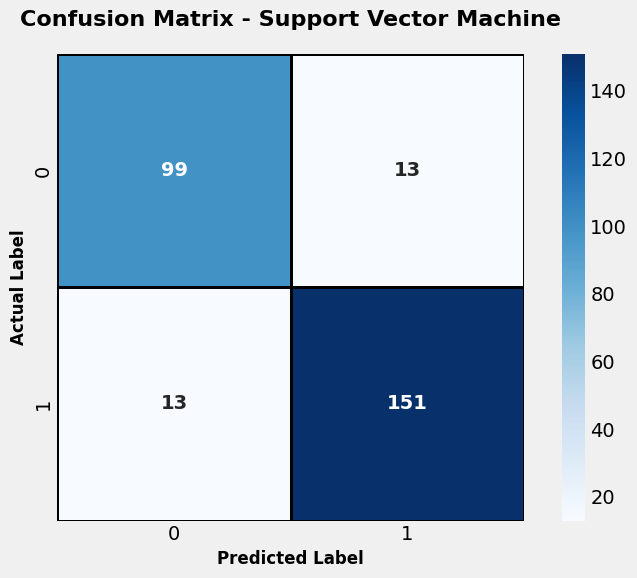

In [ ]:
from sklearn.svm import SVC

# Train and evaluate SVM model
svm = SVC()
model_name = 'Support Vector Machine'
svm_results = evaluate_model(svm, model_name, X_train, y_train, X_test, y_test)

# Plot confusion matrix secara terpisah
plot_confusion_matrix(svm_results['Confusion Matrix'], model_name)